In [ ]:
import zipfile
import pandas as pd

# Extract the uploaded ZIP
with zipfile.ZipFile("/content/Insurance_Claims_Dataset.zip") as z:
    z.extractall("/content/dataset")

# Load the five datasets
claims = pd.read_csv("/content/dataset/claims.csv")
policies = pd.read_csv("/content/dataset/policies.csv")
customers = pd.read_csv("/content/dataset/customers.csv")
incidents = pd.read_csv("/content/dataset/incidents.csv")
processing = pd.read_csv("/content/dataset/processing.csv")

datasets = {
    "Claims": claims,
    "Policies": policies,
    "Customers": customers,
    "Incidents": incidents,
    "Processing": processing
}

# Check record counts and preview the data
for name, df in datasets.items():
    print(f"\n{name}: {len(df)} rows, {len(df.columns)} columns")
    display(df.head())


Claims: 3030 rows, 8 columns


,Claim_ID,Policy_ID,Customer_ID,Incident_ID,Claim_Date,Claim_Type,Claim_Amount,Claim_Status
0,CLM000001,POL00040,CUS00040,INC000001,2025-11-09,Accident,124459.63,Pending
1,CLM000002,POL01967,CUS00167,INC000002,2026-05-04,Fire,356444.54,Pending
2,CLM000003,POL00132,CUS00132,INC000003,2025-06-06,Accident,84808.08,Settled
3,CLM000004,POL00393,CUS00393,INC000004,2025-06-27,Own Damage,22276.83,Settled
4,CLM000005,POL00621,CUS00621,INC000005,2026-02-10,Theft,385883.92,Settled



Policies: 2200 rows, 5 columns


,Policy_ID,Customer_ID,Policy_Type,Premium,Policy_Tenure_Months
0,POL00001,CUS00001,Motor,6991.22,5
1,POL00002,CUS00002,Property,37311.95,6
2,POL00003,CUS00003,Motor,16035.12,31
3,POL00004,CUS00004,Motor,11589.29,55
4,POL00005,CUS00005,Motor,9306.47,48



Customers: 1800 rows, 3 columns


,Customer_ID,Region,Customer_Tenure_Months
0,CUS00001,Karnataka,78
1,CUS00002,Karnataka,34
2,CUS00003,Tamil Nadu,121
3,CUS00004,Maharashtra,38
4,CUS00005,Telangana,96



Incidents: 3000 rows, 6 columns


,Incident_ID,Claim_ID,Incident_Date,Incident_Type,Location,Severity
0,INC000001,CLM000001,2025-11-09,Accident,Telangana,Medium
1,INC000002,CLM000002,2026-05-02,Fire,Maharashtra,Medium
2,INC000003,CLM000003,2025-06-05,Accident,Delhi,Low
3,INC000004,CLM000004,2025-06-25,Own Damage,Tamil Nadu,Low
4,INC000005,CLM000005,2026-02-07,NaN,NaN,Medium



Processing: 14471 rows, 10 columns


,Processing_ID,Claim_ID,Assignee_ID,Stage,Stage_Start_Date,Stage_End_Date,Stage_Days,Stage_Status,Settlement_Days,Investigation_Required
0,PRC000001,CLM000001,EMP012,Registration,2025-11-09,2025-11-10,1,Completed,NaN,0
1,PRC000002,CLM000001,EMP015,Document Verification,2025-11-10,2025-11-15,5,Completed,NaN,0
2,PRC000003,CLM000001,EMP029,Assessment,2025-11-15,NaN,319,In Progress,NaN,0
3,PRC000004,CLM000002,EMP007,Registration,2026-05-04,2026-05-07,3,Completed,NaN,1
4,PRC000005,CLM000002,EMP012,Document Verification,2026-05-07,NaN,146,In Progress,NaN,1


In [ ]:
for name, df in datasets.items():
    print(f"\n{'=' * 35}")
    print(name)

    print("\nData types:")
    print(df.dtypes)

    print("\nMissing values:")
    print(df.isna().sum())

    print("\nDuplicate rows:", df.duplicated().sum())

print("\nDuplicate Claim IDs:",
      claims["Claim_ID"].duplicated().sum())

print("\nClaim type variations:")
print(claims["Claim_Type"].unique())

print("\nClaim amount statistics:")
print(claims["Claim_Amount"].describe())

# Count affected claims, since durations repeat across stages
invalid = processing["Settlement_Days"] < 0

print("\nClaims with negative settlement days:",
      processing.loc[invalid, "Claim_ID"].nunique())

print("\nMissing stage end dates by stage status:")
print(
    processing.groupby("Stage_Status")["Stage_End_Date"]
    .apply(lambda values: values.isna().sum())
)


Claims

Data types:
Claim_ID         object
Policy_ID        object
Customer_ID      object
Incident_ID      object
Claim_Date       object
Claim_Type       object
Claim_Amount    float64
Claim_Status     object
dtype: object

Missing values:
Claim_ID        0
Policy_ID       0
Customer_ID     0
Incident_ID     0
Claim_Date      0
Claim_Type      0
Claim_Amount    0
Claim_Status    0
dtype: int64

Duplicate rows: 30

Policies

Data types:
Policy_ID                object
Customer_ID              object
Policy_Type              object
Premium                 float64
Policy_Tenure_Months      int64
dtype: object

Missing values:
Policy_ID               0
Customer_ID             0
Policy_Type             0
Premium                 0
Policy_Tenure_Months    0
dtype: int64

Duplicate rows: 0

Customers

Data types:
Customer_ID               object
Region                    object
Customer_Tenure_Months     int64
dtype: object

Missing values:
Customer_ID               0
Region               

In [ ]:
# Create clean copies
claims_clean = claims.copy()
policies_clean = policies.copy()
customers_clean = customers.copy()
incidents_clean = incidents.copy()
processing_clean = processing.copy()

# 1. Remove duplicate claims
claims_clean = claims_clean.drop_duplicates(
    subset="Claim_ID"
).reset_index(drop=True)

# 2. Standardise claim types
claims_clean["Claim_Type"] = (
    claims_clean["Claim_Type"].str.strip().str.title()
)

# 3. Handle missing incident details
for column in ["Incident_Type", "Location", "Severity"]:
    incidents_clean[column] = (
        incidents_clean[column]
        .fillna("Unknown")
        .str.strip()
        .str.title()
    )

# 4. Convert date columns
claims_clean["Claim_Date"] = pd.to_datetime(
    claims_clean["Claim_Date"], errors="coerce"
)

incidents_clean["Incident_Date"] = pd.to_datetime(
    incidents_clean["Incident_Date"], errors="coerce"
)

for column in ["Stage_Start_Date", "Stage_End_Date"]:
    processing_clean[column] = pd.to_datetime(
        processing_clean[column], errors="coerce"
    )

# 5. Recover invalid settlement days using completed stage dates
completed_stages = processing_clean[
    processing_clean["Stage_Status"] == "Completed"
]

claim_dates = completed_stages.groupby("Claim_ID").agg(
    First_Stage_Start=("Stage_Start_Date", "min"),
    Last_Stage_End=("Stage_End_Date", "max")
)

recovered_days = (
    claim_dates["Last_Stage_End"]
    - claim_dates["First_Stage_Start"]
).dt.days

settled_ids = claims_clean.loc[
    claims_clean["Claim_Status"] == "Settled", "Claim_ID"
]

invalid = (
    processing_clean["Settlement_Days"].lt(0)
    & processing_clean["Claim_ID"].isin(settled_ids)
)

corrected_count = processing_clean.loc[
    invalid, "Claim_ID"
].nunique()

processing_clean.loc[invalid, "Settlement_Days"] = (
    processing_clean.loc[invalid, "Claim_ID"].map(recovered_days)
)

# 6. Flag high claim amounts within each claim type
# Retain them for analysis instead of automatically deleting them
amount_groups = claims_clean.groupby("Claim_Type")["Claim_Amount"]

q1 = amount_groups.transform(lambda values: values.quantile(0.25))
q3 = amount_groups.transform(lambda values: values.quantile(0.75))

claims_clean["High_Amount_Outlier"] = (
    claims_clean["Claim_Amount"] > q3 + 1.5 * (q3 - q1)
)

# Check cleaning results
print("Unique claims:", len(claims_clean))
print("Remaining duplicate IDs:",
      claims_clean["Claim_ID"].duplicated().sum())
print("Corrected settlement durations:", corrected_count)
print("Remaining negative settlement days:",
      processing_clean["Settlement_Days"].lt(0).sum())
print("High-amount claims flagged:",
      claims_clean["High_Amount_Outlier"].sum())
print("Clean claim types:",
      claims_clean["Claim_Type"].unique())

Unique claims: 3000
Remaining duplicate IDs: 0
Corrected settlement durations: 20
Remaining negative settlement days: 0
High-amount claims flagged: 140
Clean claim types: ['Accident' 'Fire' 'Own Damage' 'Theft' 'Property Damage' 'Flood']


In [ ]:
# 1. Aggregate processing stages into one row per claim
processing_summary = processing_clean.groupby("Claim_ID").agg(
    Settlement_Days=("Settlement_Days", "first"),
    Investigation_Required=("Investigation_Required", "max"),
    Stage_Count=("Processing_ID", "count"),
    Completed_Stage_Count=(
        "Stage_Status",
        lambda values: (values == "Completed").sum()
    )
).reset_index()

# 2. Add completed stage durations as separate columns
stage_durations = (
    processing_clean[
        processing_clean["Stage_Status"] == "Completed"
    ]
    .pivot_table(
        index="Claim_ID",
        columns="Stage",
        values="Stage_Days",
        aggfunc="sum"
    )
    .add_suffix("_Days")
    .reset_index()
)

stage_durations.columns.name = None

processing_summary = processing_summary.merge(
    stage_durations,
    on="Claim_ID",
    how="left",
    validate="one_to_one"
)

# 3. Merge policies
# Customer_ID already exists in claims
master = claims_clean.merge(
    policies_clean.drop(columns="Customer_ID"),
    on="Policy_ID",
    how="left",
    validate="many_to_one"
)

# 4. Merge customers
master = master.merge(
    customers_clean,
    on="Customer_ID",
    how="left",
    validate="many_to_one"
)

# 5. Merge incident details
master = master.merge(
    incidents_clean.drop(columns="Claim_ID"),
    on="Incident_ID",
    how="left",
    validate="one_to_one"
)

# 6. Merge processing summary
master = master.merge(
    processing_summary,
    on="Claim_ID",
    how="left",
    validate="one_to_one"
)

# 7. Verify that merging did not multiply claims or amounts
assert len(master) == len(claims_clean)
assert master["Claim_ID"].is_unique
assert abs(
    master["Claim_Amount"].sum()
    - claims_clean["Claim_Amount"].sum()
) < 0.01

print("Master dataset shape:", master.shape)
print("Unique claims:", master["Claim_ID"].nunique())
print("Merge checks passed!")

display(master.head())

Master dataset shape: (3000, 28)
Unique claims: 3000
Merge checks passed!


,Claim_ID,Policy_ID,Customer_ID,Incident_ID,Claim_Date,Claim_Type,Claim_Amount,Claim_Status,High_Amount_Outlier,Policy_Type,...,Settlement_Days,Investigation_Required,Stage_Count,Completed_Stage_Count,Approval_Days,Assessment_Days,Document Verification_Days,Investigation_Days,Payment_Days,Registration_Days
0,CLM000001,POL00040,CUS00040,INC000001,2025-11-09,Accident,124459.63,Pending,False,Motor,...,NaN,0,3,2,NaN,NaN,5.0,NaN,NaN,1.0
1,CLM000002,POL01967,CUS00167,INC000002,2026-05-04,Fire,356444.54,Pending,False,Property,...,NaN,1,2,1,NaN,NaN,NaN,NaN,NaN,3.0
2,CLM000003,POL00132,CUS00132,INC000003,2025-06-06,Accident,84808.08,Settled,False,Motor,...,15.0,0,5,5,1.0,2.0,9.0,NaN,2.0,1.0
3,CLM000004,POL00393,CUS00393,INC000004,2025-06-27,Own Damage,22276.83,Settled,False,Motor,...,15.0,0,5,5,3.0,6.0,4.0,NaN,1.0,1.0
4,CLM000005,POL00621,CUS00621,INC000005,2026-02-10,Theft,385883.92,Settled,False,Motor,...,27.0,0,5,5,2.0,8.0,7.0,NaN,3.0,7.0


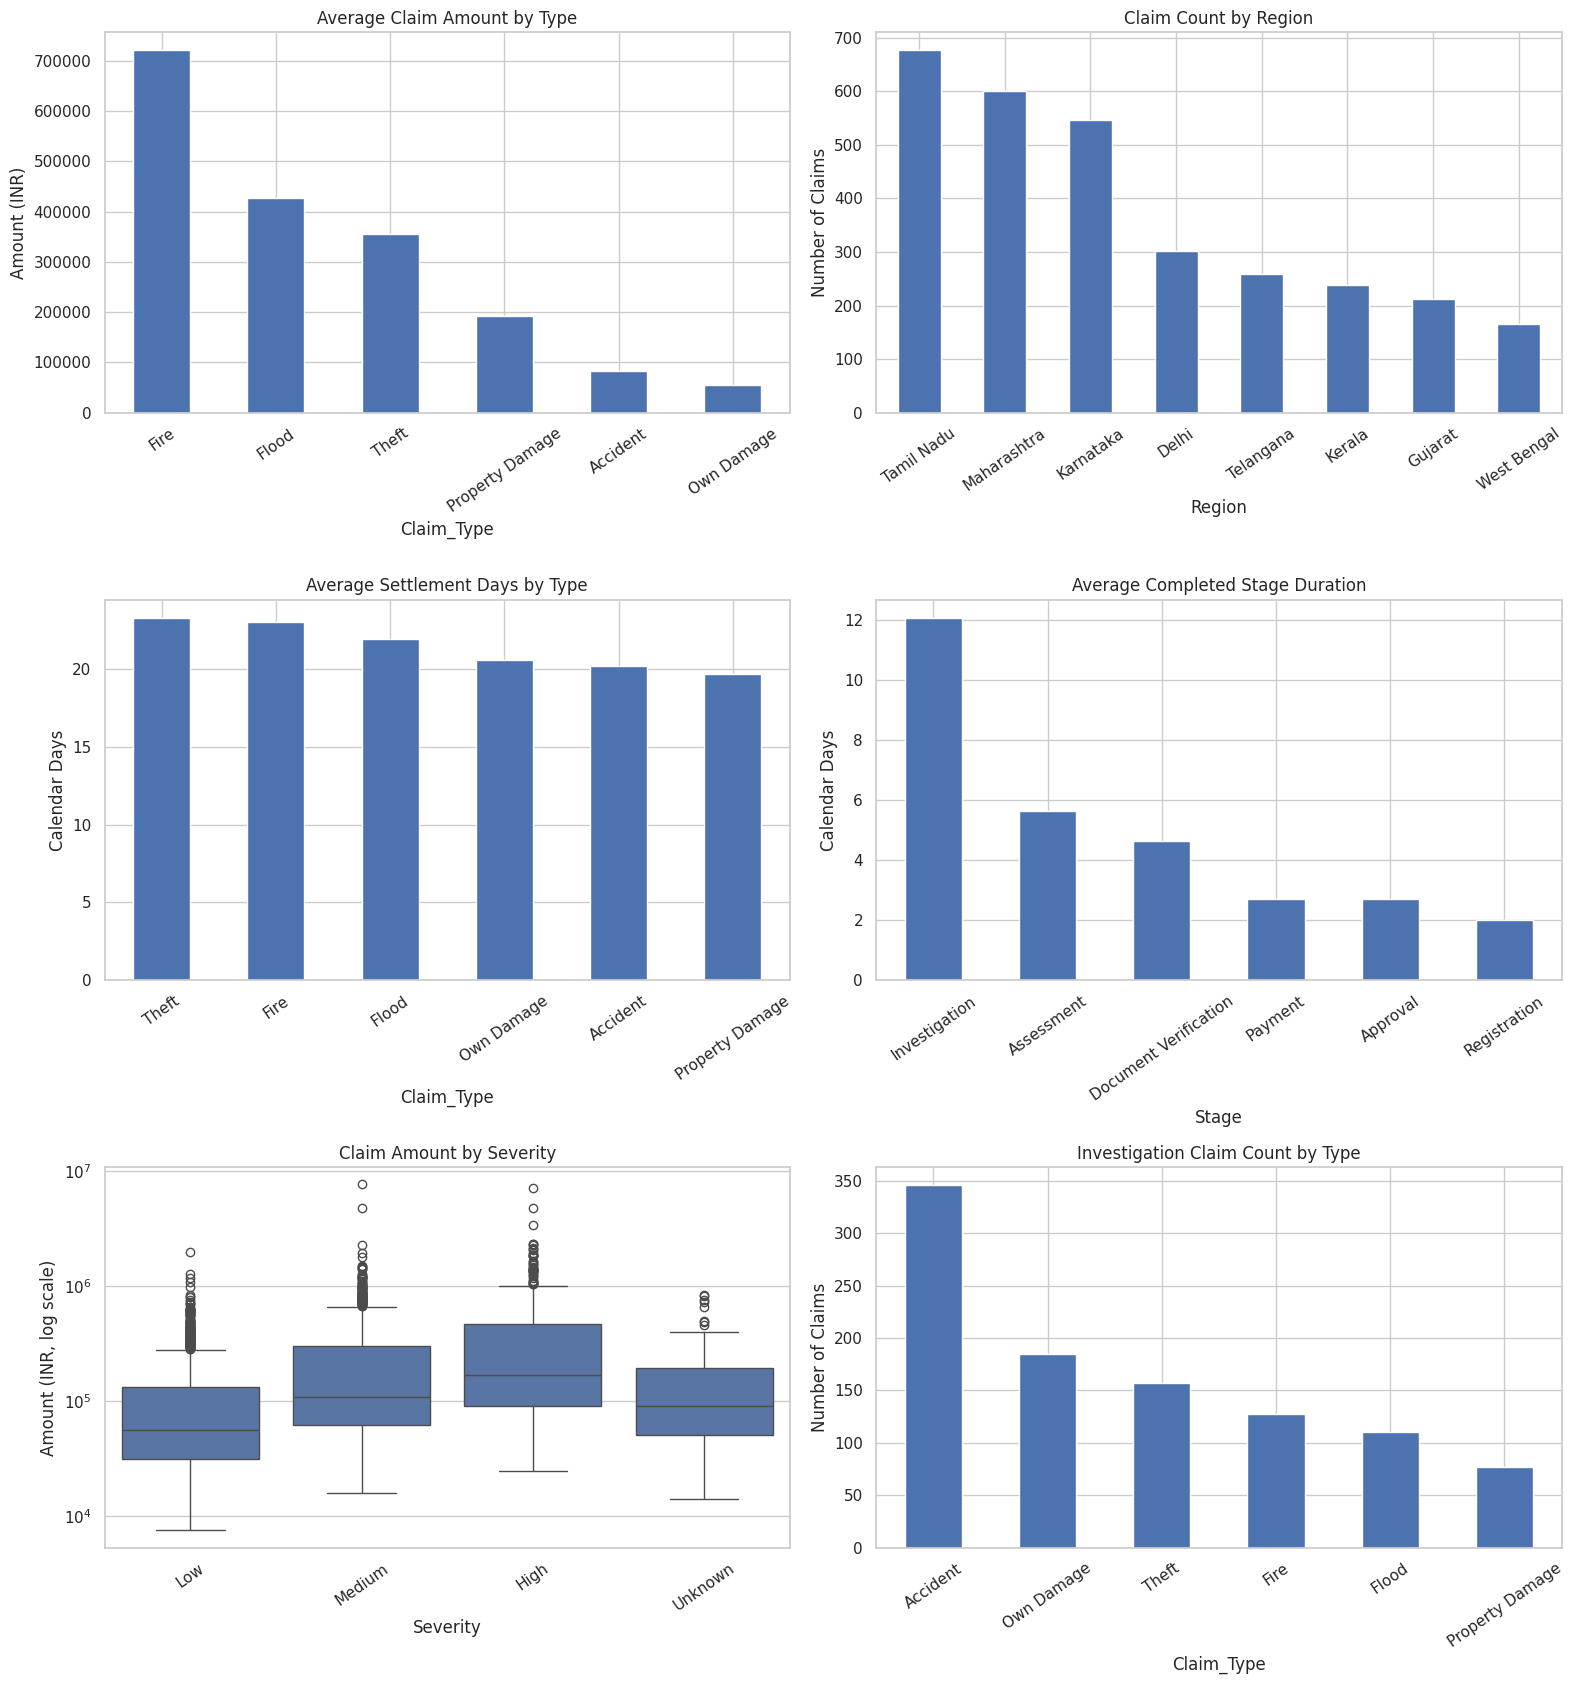


ACTUAL FINDINGS
Highest average claim amount: Fire — INR 720,831.68
Highest claim volume: Tamil Nadu — 676 claims
Longest average settlement time: Theft — 23.31 days
Longest average completed stage: Investigation — 12.08 days


,Total_Claims,Investigation_Claims,Investigation_Rate_Percent
Claim_Type,,,
Accident,1195,346,28.95
Fire,256,128,50.00
Flood,336,110,32.74
Own Damage,608,185,30.43
Property Damage,290,77,26.55
Theft,315,157,49.84


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Average claim amount by type
amount_by_type = (
    master.groupby("Claim_Type")["Claim_Amount"]
    .mean().sort_values(ascending=False)
)

# 2. Claim count by region
claims_by_region = master["Region"].value_counts()

# 3. Settlement time: settled claims only
settled = master[
    (master["Claim_Status"] == "Settled")
    & master["Settlement_Days"].ge(0)
].copy()

settlement_by_type = (
    settled.groupby("Claim_Type")["Settlement_Days"]
    .mean().sort_values(ascending=False)
)

# 4. Average completed stage duration
completed = processing_clean[
    processing_clean["Stage_Status"] == "Completed"
]

stage_delay = (
    completed.groupby("Stage")["Stage_Days"]
    .mean().sort_values(ascending=False)
)

# 5. Investigation workload: one row per claim
investigation = master.groupby("Claim_Type").agg(
    Total_Claims=("Claim_ID", "count"),
    Investigation_Claims=("Investigation_Required", "sum")
)

investigation["Investigation_Rate_Percent"] = (
    investigation["Investigation_Claims"]
    / investigation["Total_Claims"] * 100
)

# Create six charts
fig, axes = plt.subplots(3, 2, figsize=(16, 17))

amount_by_type.plot.bar(
    ax=axes[0, 0], title="Average Claim Amount by Type"
)
axes[0, 0].set_ylabel("Amount (INR)")

claims_by_region.plot.bar(
    ax=axes[0, 1], title="Claim Count by Region"
)
axes[0, 1].set_ylabel("Number of Claims")

settlement_by_type.plot.bar(
    ax=axes[1, 0], title="Average Settlement Days by Type"
)
axes[1, 0].set_ylabel("Calendar Days")

stage_delay.plot.bar(
    ax=axes[1, 1], title="Average Completed Stage Duration"
)
axes[1, 1].set_ylabel("Calendar Days")

sns.boxplot(
    data=master,
    x="Severity",
    y="Claim_Amount",
    order=["Low", "Medium", "High", "Unknown"],
    ax=axes[2, 0]
)
axes[2, 0].set_yscale("log")
axes[2, 0].set_title("Claim Amount by Severity")
axes[2, 0].set_ylabel("Amount (INR, log scale)")

investigation["Investigation_Claims"].sort_values(
    ascending=False
).plot.bar(
    ax=axes[2, 1], title="Investigation Claim Count by Type"
)
axes[2, 1].set_ylabel("Number of Claims")

for ax in axes.flat:
    ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.savefig("/content/EDA_Charts.png", dpi=200)
plt.show()

# Actual findings for your answer sheet
print("\nACTUAL FINDINGS")
print(
    f"Highest average claim amount: {amount_by_type.index[0]} "
    f"— INR {amount_by_type.iloc[0]:,.2f}"
)
print(
    f"Highest claim volume: {claims_by_region.index[0]} "
    f"— {claims_by_region.iloc[0]} claims"
)
print(
    f"Longest average settlement time: {settlement_by_type.index[0]} "
    f"— {settlement_by_type.iloc[0]:.2f} days"
)
print(
    f"Longest average completed stage: {stage_delay.index[0]} "
    f"— {stage_delay.iloc[0]:.2f} days"
)

display(investigation.round(2))

In [ ]:
import numpy as np

# 1. Extract claim month and year
master["Claim_Month"] = master["Claim_Date"].dt.month
master["Claim_Year"] = master["Claim_Date"].dt.year

# 2. Claim-to-premium ratio
master["Claim_to_Premium_Ratio"] = (
    master["Claim_Amount"]
    / master["Premium"].where(master["Premium"] > 0)
)

# 3. Group policy tenure
master["Policy_Tenure_Group"] = pd.cut(
    master["Policy_Tenure_Months"],
    bins=[0, 12, 36, np.inf],
    labels=["Up to 1 Year", "1–3 Years", "Above 3 Years"]
)

# 4. Select inputs available when a claim is submitted
numeric_features = [
    "Claim_Amount",
    "Premium",
    "Policy_Tenure_Months",
    "Customer_Tenure_Months",
    "Claim_Month",
    "Claim_to_Premium_Ratio"
]

categorical_features = [
    "Claim_Type",
    "Policy_Type",
    "Region",
    "Incident_Type",
    "Severity"
]

selected_features = numeric_features + categorical_features
target = "Settlement_Days"

# 5. Use only settled claims with valid target values
model_data = master.loc[
    (master["Claim_Status"] == "Settled")
    & master[target].notna()
    & master[target].ge(0),
    selected_features + [target, "Claim_Date"]
].copy()

# 6. Prepare inputs and target
X = model_data[selected_features].copy()
y = model_data[target].copy()

print("Claims available for modelling:", len(model_data))
print("Number of selected input features:", len(selected_features))
print("Target:", target)

display(
    master[
        ["Claim_ID", "Claim_Month", "Claim_to_Premium_Ratio",
         "Policy_Tenure_Group"]
    ].head()
)

Claims available for modelling: 2355
Number of selected input features: 11
Target: Settlement_Days


,Claim_ID,Claim_Month,Claim_to_Premium_Ratio,Policy_Tenure_Group
0,CLM000001,11,5.289582,1–3 Years
1,CLM000002,5,14.885230,1–3 Years
2,CLM000003,6,9.128375,Above 3 Years
3,CLM000004,6,1.173967,1–3 Years
4,CLM000005,2,39.210904,Above 3 Years


Training claims: 1884
Testing claims: 471


,MAE_Days,RMSE_Days,R2
Mean Baseline,6.628,8.205,-0.000
Random Forest,5.673,6.985,0.275


,Actual_Days,Predicted_Days
2431,20.0,19.38
858,10.0,17.11
886,17.0,16.34
2640,20.0,21.04
1484,25.0,15.34
2524,19.0,15.55
484,22.0,24.75
150,17.0,22.29
1492,15.0,26.13
2519,15.0,15.55


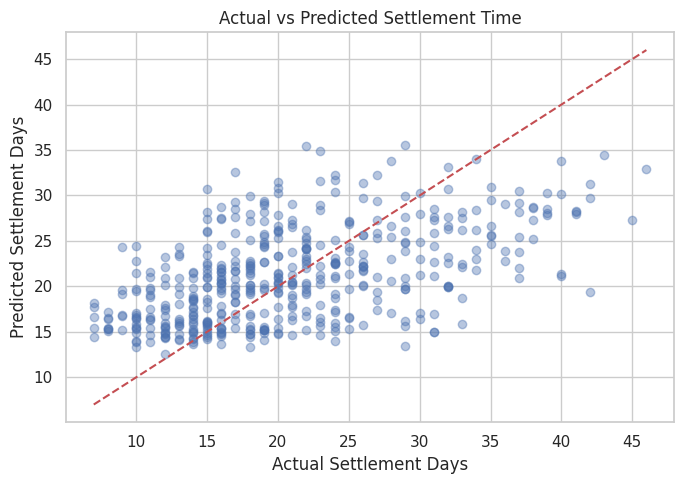

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# 2. Prepare numerical and categorical inputs
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# 3. Create and train the model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)
predictions = model.predict(X_test)

# 4. Compare against a simple average prediction
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)

def evaluate(actual, predicted):
    return {
        "MAE_Days": mean_absolute_error(actual, predicted),
        "RMSE_Days": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    }

performance = pd.DataFrame({
    "Mean Baseline": evaluate(y_test, baseline_predictions),
    "Random Forest": evaluate(y_test, predictions)
}).T

print("Training claims:", len(X_train))
print("Testing claims:", len(X_test))
display(performance.round(3))

# 5. Compare actual and predicted settlement time
prediction_results = pd.DataFrame({
    "Actual_Days": y_test,
    "Predicted_Days": predictions
})

display(prediction_results.head(10).round(2))

plt.figure(figsize=(7, 5))
plt.scatter(y_test, predictions, alpha=0.4)

lower = min(y_test.min(), predictions.min())
upper = max(y_test.max(), predictions.max())
plt.plot([lower, upper], [lower, upper], "r--")

plt.xlabel("Actual Settlement Days")
plt.ylabel("Predicted Settlement Days")
plt.title("Actual vs Predicted Settlement Time")
plt.tight_layout()
plt.show()

,Feature,MAE_Increase_Days,Variation_Days
10,Severity,1.439,0.147
8,Region,0.357,0.068
2,Policy_Tenure_Months,0.048,0.040
4,Claim_Month,-0.004,0.020
7,Policy_Type,-0.004,0.002
6,Claim_Type,-0.015,0.006
9,Incident_Type,-0.015,0.007
3,Customer_Tenure_Months,-0.025,0.019
5,Claim_to_Premium_Ratio,-0.030,0.034
0,Claim_Amount,-0.059,0.023


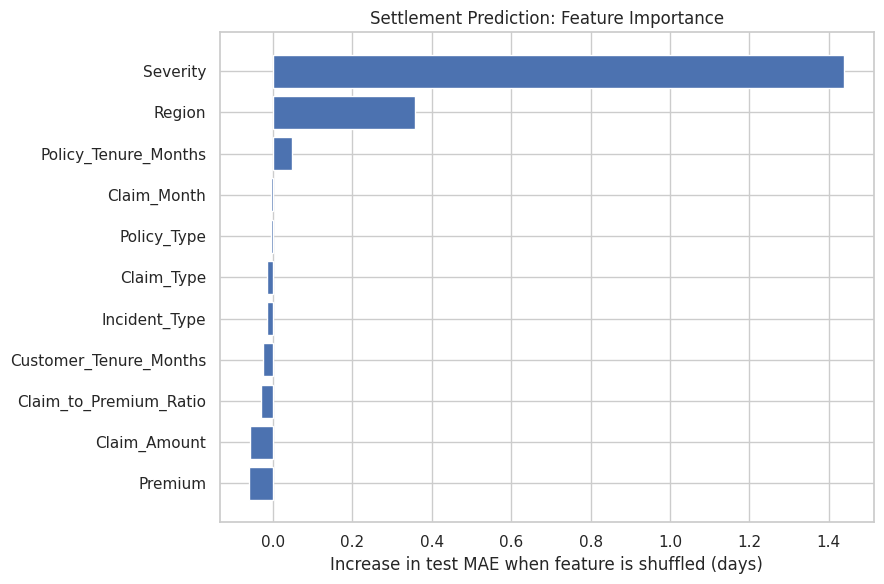

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from sklearn.inspection import permutation_importance
from pathlib import Path
import shutil

# 1. Feature importance using test data
importance_result = permutation_importance(
    model,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "Feature": selected_features,
    "MAE_Increase_Days": importance_result.importances_mean,
    "Variation_Days": importance_result.importances_std
}).sort_values("MAE_Increase_Days", ascending=False)

display(feature_importance.round(3))

plt.figure(figsize=(9, 6))
plt.barh(
    feature_importance["Feature"][::-1],
    feature_importance["MAE_Increase_Days"][::-1]
)
plt.xlabel("Increase in test MAE when feature is shuffled (days)")
plt.title("Settlement Prediction: Feature Importance")
plt.tight_layout()
plt.savefig("/content/Feature_Importance.png", dpi=200)
plt.show()

# 2. Prepare files for Excel analysis
export_folder = Path("/content/Insurance_Analysis_Outputs")
export_folder.mkdir(exist_ok=True)

master.to_csv(
    export_folder / "cleaned_master.csv", index=False
)
processing_clean.to_csv(
    export_folder / "cleaned_processing.csv", index=False
)
performance.to_csv(
    export_folder / "model_performance.csv",
    index_label="Model"
)
feature_importance.to_csv(
    export_folder / "feature_importance.csv", index=False
)
prediction_results.to_csv(
    export_folder / "prediction_results.csv", index=False
)

# 3. Save EDA summary tables
amount_by_type.rename("Average_Claim_Amount").to_csv(
    export_folder / "claim_amount_by_type.csv"
)
claims_by_region.rename_axis("Region").rename("Claim_Count").to_csv(
    export_folder / "regional_claims.csv"
)
settlement_by_type.rename("Average_Settlement_Days").to_csv(
    export_folder / "settlement_by_type.csv"
)
stage_delay.rename("Average_Completed_Stage_Days").to_csv(
    export_folder / "stage_duration.csv"
)
investigation.to_csv(
    export_folder / "investigation_workload.csv"
)

# 4. Include charts and create ZIP
for filename in ["EDA_Charts.png", "Feature_Importance.png"]:
    shutil.copy(
        Path("/content") / filename,
        export_folder / filename
    )

zip_path = shutil.make_archive(
    "/content/Insurance_Analysis_Outputs",
    "zip",
    export_folder
)

# 5. Download the results
from google.colab import files
files.download(zip_path)

In [9]:
display(performance.round(3))

,MAE_Days,RMSE_Days,R2
Mean Baseline,6.628,8.205,-0.000
Random Forest,5.673,6.985,0.275


In [10]:
print("Average claim amount by type:")
print(amount_by_type.round(2))

print("\nRegional claim counts:")
print(claims_by_region)

print("\nAverage settlement days by type:")
print(settlement_by_type.round(2))

print("\nAverage completed stage duration:")
print(stage_delay.round(2))

print("\nInvestigation workload:")
display(investigation.round(2))

Average claim amount by type:
Claim_Type
Fire               720831.68
Flood              427436.47
Theft              355288.57
Property Damage    192639.68
Accident            83002.06
Own Damage          54462.82
Name: Claim_Amount, dtype: float64

Regional claim counts:
Region
Tamil Nadu     676
Maharashtra    600
Karnataka      547
Delhi          301
Telangana      259
Kerala         239
Gujarat        212
West Bengal    166
Name: count, dtype: int64

Average settlement days by type:
Claim_Type
Theft              23.31
Fire               23.03
Flood              21.96
Own Damage         20.58
Accident           20.22
Property Damage    19.71
Name: Settlement_Days, dtype: float64

Average completed stage duration:
Stage
Investigation            12.08
Assessment                5.65
Document Verification     4.65
Payment                   2.71
Approval                  2.70
Registration              2.00
Name: Stage_Days, dtype: float64

Investigation workload:


,Total_Claims,Investigation_Claims,Investigation_Rate_Percent
Claim_Type,,,
Accident,1195,346,28.95
Fire,256,128,50.00
Flood,336,110,32.74
Own Damage,608,185,30.43
Property Damage,290,77,26.55
Theft,315,157,49.84
